# HazeCast SG: Exploratory Data Analysis

**Data team:** Maria and Anu  ·  **Data:** April 2014 to 18 October 2026

**EDA** means looking closely at the data *before* building anything, to learn how it behaves.
Each section below asks one plain question, answers it with a chart, and then says what we decided because of it.

The numbers come from `src/hazecast/eda.py`. Running `python -m hazecast.eda` saves the same
tables to `reports/eda/`, so the findings can be checked without this notebook.

| # | Question | Short answer |
|---|---|---|
| 1 | [What data do we have?](#q1) | 12 years, three sources, all hourly or daily |
| 2 | [How high does PM2.5 go?](#q2) | Usually about 12. Unhealthy about 1% of the time |
| 2b | [What is happening in 2026?](#q2b) | A major haze season, happening right now |
| 3 | [When does haze happen?](#q3) | August to November, when the fires burn |
| 4 | [Does time of day matter?](#q4) | Hardly at all |
| 5 | [Do the regions behave alike?](#q5) | Yes, very closely |
| 6 | [How long do fires matter?](#q6) | For days, fading slowly. Sumatra matters more |
| 7 | [Which way does the wind blow on haze days?](#q7) | From the south and east, towards the fires |
| 8 | [Does rain help?](#q8) | A little |
| 9 | [How much does "now" tell us about "later"?](#q9) | A lot for the next few hours |

To run it, open in JupyterLab from the project folder, then **Run > Run All Cells**
(about 1 minute). The raw files must be in `data/raw/` first.

In [1]:
# Setup: finds the project code and builds the clean (silver) data. You can skip reading this cell.
import sys, logging, warnings
from pathlib import Path
import pandas as pd

repo_root = Path.cwd()
if not (repo_root / "src" / "hazecast").exists():
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root / "src")); sys.path.insert(0, str(repo_root / "notebooks"))
logging.basicConfig(level=logging.ERROR); warnings.filterwarnings("ignore")

from hazecast.ingest import pm25 as ip, weather as iw, firms as iff
from hazecast import bronze_to_silver as b2s, eda
import data_story_helpers as h

ip.write_bronze(ip.load_pm25_bronze()); iw.write_bronze(iw.load_weather_bronze()); iff.write_bronze(iff.load_firms_bronze())
pm25 = b2s.pm25_silver(); weather = b2s.weather_silver(); firms = b2s.firms_daily_silver()
print("Ready.")

Ready.


<a id="q1"></a>
## 1. What Data Do We Have?

In [2]:
eda.overview(pm25, weather, firms)

,source,size,from,to,detail
0,PM2.5,"110,015 hours",2014-04-01 01:00:00,2026-10-18 23:00:00,5 regions + national average
1,Weather,"549,840 place-hours",2014-04-01 00:00:00,2026-10-16 23:00:00,5 places
2,Fires,"4,672 days",2014-01-01 00:00:00,2026-10-16 00:00:00,daily counts for Sumatra and Kalimantan


All three sources cover the same 12 years, including the big haze seasons of
2015 and 2019, and the 2026 season that is happening now. That gives the model real haze to learn from and to be tested on.

<a id="q2"></a>
## 2. How High Does PM2.5 Go?

NEA calls PM2.5 **unhealthy from 56 µg/m³**. How often do we get there?

In [3]:
eda.pm25_spread(pm25)

,measure,value
0,Typical hour (median),12
1,1 hour in 10 is above,23
2,1 hour in 100 is above,64
3,"1 hour in 1,000 is above",147
4,Share of hours unhealthy (56 or more),1.3%


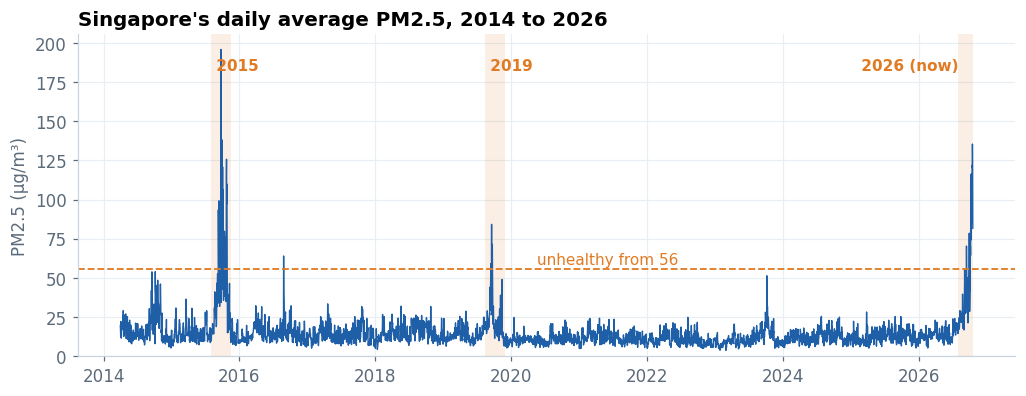

In [4]:
h.plot_pm25_history(pm25);

A typical hour is about 12. Unhealthy hours are **rare** (about 1%), and almost
all of them were in 2015 and the 2026 season. A model could look accurate "on average" while missing
every haze hour, so we must also measure **how many unhealthy hours it catches**.

<a id="q2b"></a>
## 2b. What Is Happening in 2026?

The newest data runs to 18 October 2026, in the middle of this year's dry season.

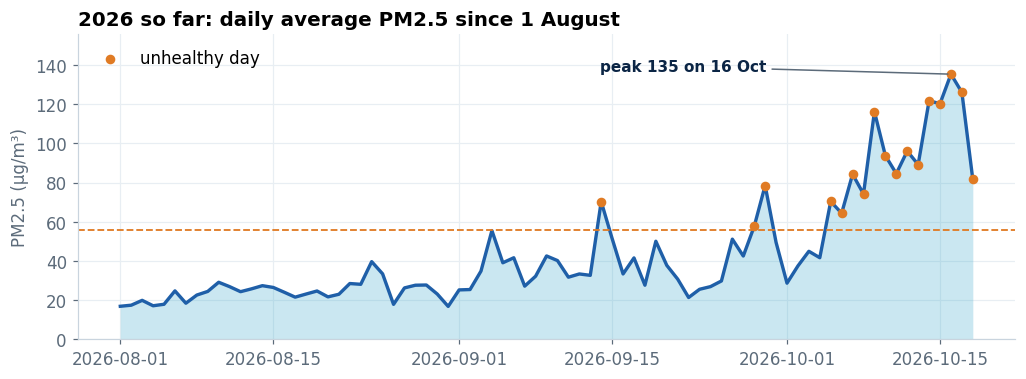

,unhealthy days so far,highest daily average,on
0,17,135,16 Oct 2026


In [5]:
h.plot_season_2026(pm25)

2026 is the **second-worst haze season** in our data, after 2015, and it is still
going. It is not yet used for testing because the season has not ended. To keep a future test fair,
**it was also kept out of feature selection**. Once it ends, it can become a third test season.

<a id="q3"></a>
## 3. When Does Haze Happen?

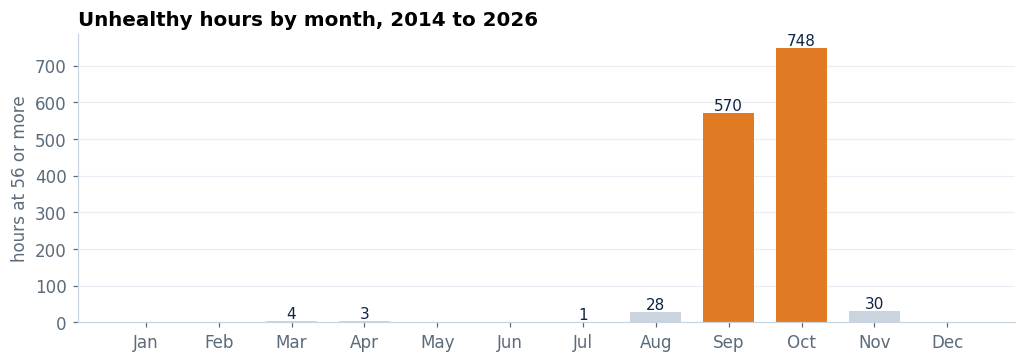

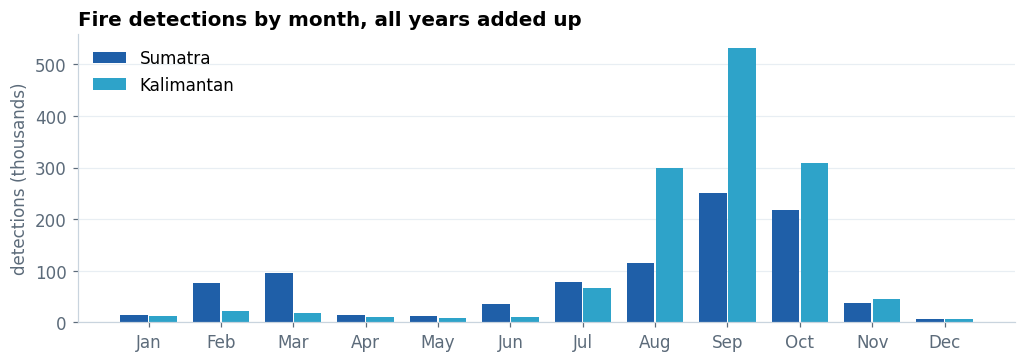

In [6]:
months = eda.by_month(pm25, firms)
h.plot_unhealthy_by_month(months)
h.plot_fires_by_month(months)

Almost every unhealthy hour falls between **August and November**, exactly when
the fires peak. Fire counts are clearly a useful input. It is also why the model is tested on
whole haze seasons, not random hours.

<a id="q4"></a>
## 4. Does Time of Day Matter?

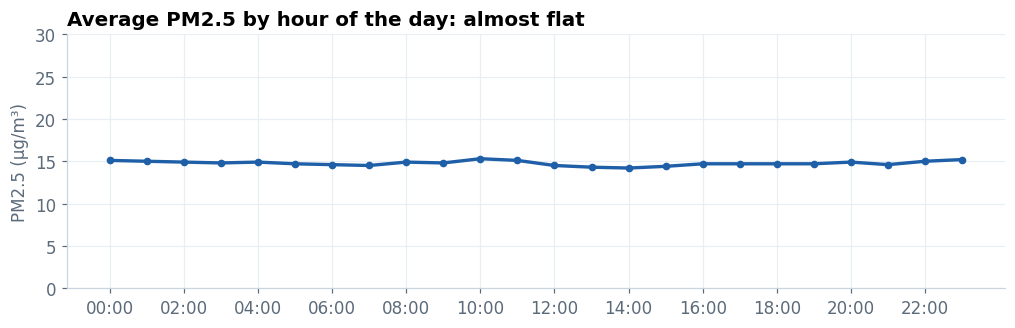

In [7]:
h.plot_by_hour(eda.by_hour(pm25))

The average barely moves across the day (about 14 to 15). Unlike traffic
pollution, haze does not follow a daily rhythm, so **we did not add an hour-of-day feature**.

<a id="q5"></a>
## 5. Do the Regions Behave Alike?

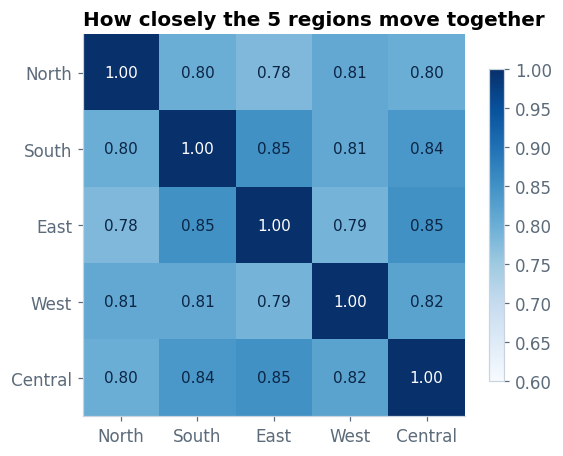

In [8]:
h.plot_region_similarity(eda.region_similarity(pm25))

The 5 regions move closely together, because haze blankets the whole island.
**One shared set of features works for every region**, and a national average is meaningful.

<a id="q6"></a>
## 6. How Long Do Fires Matter?

We compared today's PM2.5 with the number of fires today, yesterday, and up to a week ago.

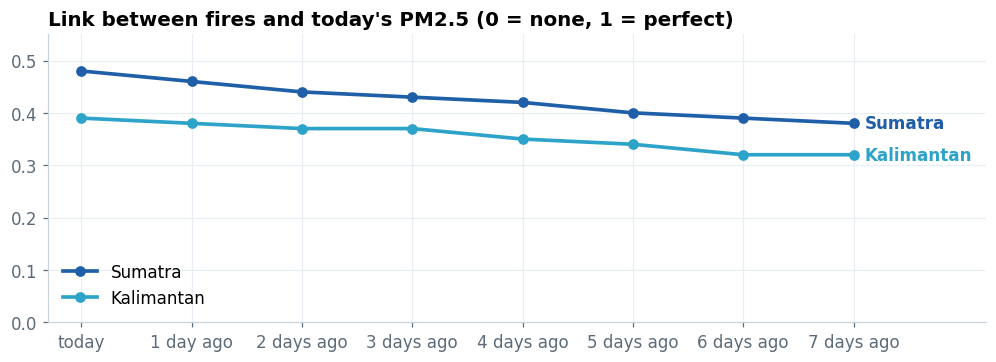

In [9]:
lag = eda.fire_lag_link(pm25, firms)
h.plot_fire_lag(lag)

The link is strongest for today's fires but fades **slowly** over a week, because
smoke takes time to travel and to clear. That is why the features include fires from several days
back and **3-day and 7-day totals**. Sumatra matters more than Kalimantan: it is closer.

<a id="q7"></a>
## 7. Which Way Does the Wind Blow on Haze Days?

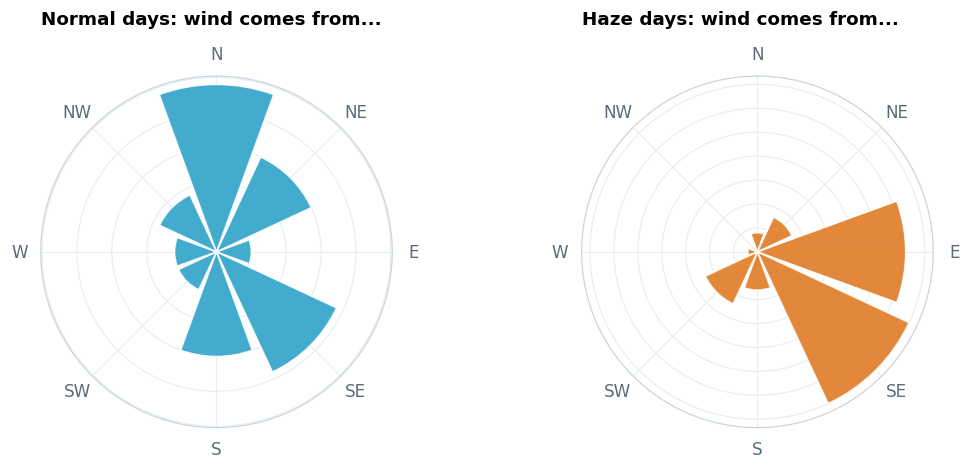

day,haze days,normal days
from,,
N,4.0,24.0
NE,8.0,15.0
E,31.0,5.0
SE,35.0,19.0
S,8.0,15.0
SW,12.0,6.0
W,2.0,6.0
NW,0.0,9.0


In [10]:
wind = eda.wind_on_haze_days(pm25, weather)
h.plot_wind_roses(wind)
wind

On normal days the wind often comes from the north. On haze days it comes
from the **south and east**, the direction of the fires, and **almost never from the north**.
Fires only become haze when the wind carries the smoke here. This is why the gold table has
**"upwind" features** that combine fire counts with wind direction.

<a id="q8"></a>
## 8. Does Rain Help?

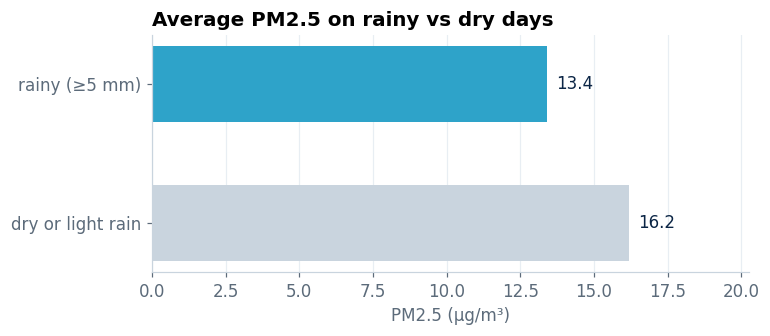

In [11]:
h.plot_rain_effect(eda.rain_effect(pm25, weather))

Rainy days are a bit cleaner, because rain washes particles out of the air.
The effect is small but real, so **rain totals are kept as features**.

<a id="q9"></a>
## 9. How Much Does "Now" Tell Us About "Later"?

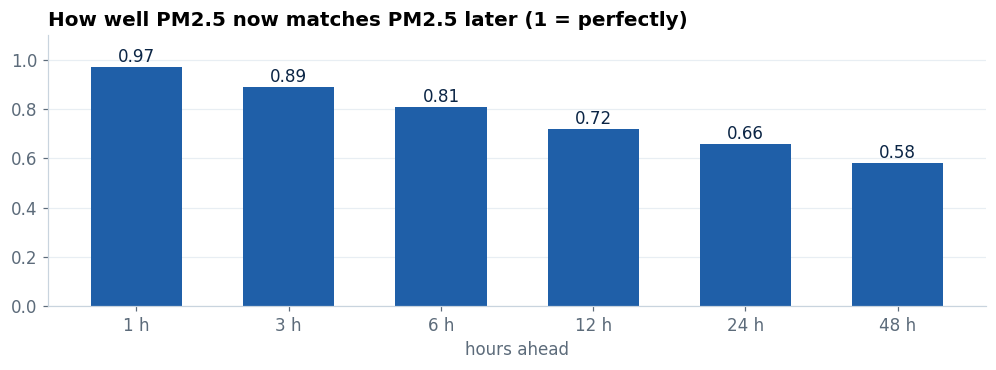

In [12]:
h.plot_persistence(eda.persistence(pm25))

The reading 1 hour from now almost always matches the reading now (0.97).
The match weakens as we look further ahead. So the **current readings must always be features**,
and any model has to beat the simple guess "it will stay the same". The real value of a model is
further ahead, where this simple guess gets worse.

## From Findings to Decisions

| What we found | What we did |
|---|---|
| Haze is rare and seasonal | Test on whole haze seasons; report unhealthy hours caught, not just average error |
| Time of day hardly matters | No hour-of-day feature |
| Regions move together | One feature set for all regions |
| Fires matter for days | Fire counts for today and 1 to 3 days back, plus 3-day and 7-day totals |
| Wind direction decides if smoke arrives | "Upwind" features that combine fires and wind |
| Rain cleans the air a little | Rain totals kept |
| Now predicts the next few hours | Current readings always kept as features |

**Next:** `02_cleaning_and_feature_selection.ipynb` shows how the data was cleaned and how the
56 features were cut to 36.